# 02 · Replicate DANE's 2025 monetary poverty and Gini

**Question:** starting from the microdata, do we get DANE's published 2025 figures?
**Target:** each estimate rounds to DANE's published value (1 decimal for rates, 3 for Gini).

Definitions used (from DANE's methodology and the 2025 data dictionary):
- income concept = per-capita income of the **spending unit** (*unidad de gasto*, UG: the household
  minus domestic workers, boarders (*pensionistas*) and their relatives living in it)
- unit of analysis = **all persons in the household**, each assigned the UG's per-capita income,
  so each household row represents `fex_c × nper` persons
  (weighting by `npersug` instead gives 28.05% / Gini 0.530; `nper` reproduces DANE exactly)
- `pobre` = 1 if `ingpcug < lp`; `indigente` = 1 if `ingpcug < li` (lines vary across 50 domains)
- `clase` 1 = cabeceras (urban), 2 = centros poblados y rural disperso

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from povcol.load import load
from povcol.weighted import weighted_rate, gini
from povcol import official

YEAR = 2025
RESULTS = ROOT / "results"; RESULTS.mkdir(exist_ok=True)
FIGS = ROOT / "figures"; FIGS.mkdir(exist_ok=True)

hog = load(YEAR, "hogares")
hog["w_person"] = hog["fex"] * hog["nper"]
DOMAINS = {"nacional": hog, "cabeceras": hog[hog["clase"] == 1], "rural": hog[hog["clase"] == 2]}

## 1. Replication table

In [2]:
rows = []
for dom, d in DOMAINS.items():
    w = d["w_person"]
    mine = {
        "Monetary poverty (%)": weighted_rate(d["pobre"], w),
        "Extreme poverty (%)": weighted_rate(d["indigente"], w),
        "Gini": gini(d["ingpcug"], w),
    }
    dane = {
        "Monetary poverty (%)": official.POVERTY[(YEAR, dom)],
        "Extreme poverty (%)": official.EXTREME[(YEAR, dom)],
        "Gini": official.GINI[(YEAR, dom)],
    }
    for ind in mine:
        rows.append({"domain": dom, "indicator": ind, "this_repo": mine[ind], "DANE": dane[ind]})

rep = pd.DataFrame(rows)
rep["difference"] = rep["this_repo"] - rep["DANE"]
rep["rounds_to_DANE"] = np.where(rep["indicator"] == "Gini",
                                 rep["this_repo"].round(3) == rep["DANE"],
                                 rep["this_repo"].round(1) == rep["DANE"])
rep.to_csv(RESULTS / "replication_2025.csv", index=False)
rep.round(3)

,domain,indicator,this_repo,DANE,difference,rounds_to_DANE
0,nacional,Monetary poverty (%),28.003,28.000,0.003,True
1,nacional,Extreme poverty (%),9.638,9.600,0.038,True
2,nacional,Gini,0.531,0.531,-0.000,True
3,cabeceras,Monetary poverty (%),24.608,24.600,0.008,True
4,cabeceras,Extreme poverty (%),6.853,6.900,-0.047,True
5,cabeceras,Gini,0.507,0.507,0.000,True
6,rural,Monetary poverty (%),39.484,39.500,-0.016,True
7,rural,Extreme poverty (%),19.057,19.100,-0.043,True
8,rural,Gini,0.476,0.476,0.000,True


**Cross-check with a second variable.** The file also has `npobres` (number of poor persons in
the household). Computing the rate from it is an independent route to the same number.

In [3]:
w = hog["w_person"]
via_flag = weighted_rate(hog["pobre"], w)
via_count = 100 * (hog["fex"] * hog["npobres"]).sum() / w.sum()
print(f"via pobre flag:  {via_flag:.3f}%")
print(f"via npobres:     {via_count:.3f}%")

via pobre flag:  28.003%
via npobres:     28.003%


## 2. Why the weights matter

Four ways to compute "the" national poverty rate from the same file. Only the last one is the
population estimate. The others make one or both of two mistakes:
- **wrong unit** — counting households instead of persons (poor households are larger)
- **no weights** — treating every sampled household as representing the same number of people

In [4]:
d = hog
methods = pd.DataFrame({
    "method": [
        "Unweighted, households (row mean)",
        "Weighted, households (fex only)",
        "Unweighted, persons (nper only)",
        "Weighted, persons (fex × nper)  ← official",
    ],
    "rate": [
        weighted_rate(d["pobre"]),
        weighted_rate(d["pobre"], d["fex"]),
        weighted_rate(d["pobre"], d["nper"]),
        weighted_rate(d["pobre"], d["w_person"]),
    ],
})
methods["gap_vs_official_pp"] = methods["rate"] - official.POVERTY[(YEAR, "nacional")]
methods.to_csv(RESULTS / "weights_comparison_2025.csv", index=False)
methods.round(2)

,method,rate,gap_vs_official_pp
0,"Unweighted, households (row mean)",24.20,-3.80
1,"Weighted, households (fex only)",22.35,-5.65
2,"Unweighted, persons (nper only)",29.91,1.91
3,"Weighted, persons (fex × nper) ← official",28.00,0.00


**Where the bias comes from: the sample is not proportional to the population.**
DANE oversamples the 23 capital cities (each gets ~6,000–12,000 households regardless of size)
and rural areas get a smaller share of the sample than of the population.

In [5]:
by_domain = (hog.groupby("dominio")
                .agg(sample_households=("pobre", "size"), population=("w_person", "sum"))
                .assign(sample_share=lambda x: 100 * x.sample_households / x.sample_households.sum(),
                        population_share=lambda x: 100 * x.population / x.population.sum())
                .assign(sampling_ratio=lambda x: x.sample_share / x.population_share)
                .sort_values("sampling_ratio", ascending=False))
by_domain[["sample_households", "sample_share", "population_share", "sampling_ratio"]].round(2)

,sample_households,sample_share,population_share,sampling_ratio
dominio,,,,
QUIBDO,8305,3.00,0.22,13.52
FLORENCIA,8021,2.90,0.31,9.26
TUNJA,7929,2.87,0.35,8.25
RIOHACHA,6485,2.34,0.31,7.51
POPAYAN,8006,2.89,0.53,5.44
ARMENIA,9233,3.34,0.61,5.43
PASTO,8900,3.22,0.60,5.39
SINCELEJO,6931,2.51,0.52,4.77
MANIZALES,11639,4.21,0.99,4.27


In [6]:
rural = hog["clase"] == 2
print(f"Rural: {100*rural.mean():.1f}% of sampled households, "
      f"{100*hog.loc[rural, 'w_person'].sum()/hog['w_person'].sum():.1f}% of the population")

Rural: 13.5% of sampled households, 22.8% of the population


## 3. Chart

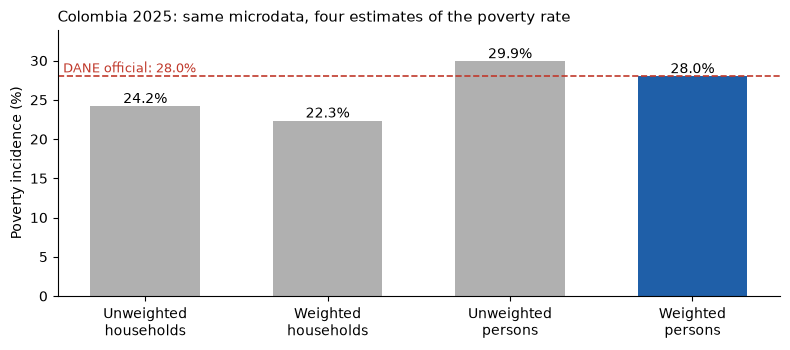

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
labels = ["Unweighted\nhouseholds", "Weighted\nhouseholds", "Unweighted\npersons", "Weighted\npersons"]
colors = ["#b0b0b0", "#b0b0b0", "#b0b0b0", "#1f5fa8"]
bars = ax.bar(labels, methods["rate"], color=colors, width=0.6)
ax.axhline(official.POVERTY[(YEAR, "nacional")], color="#c0392b", lw=1.2, ls="--")
ax.text(-0.45, official.POVERTY[(YEAR, "nacional")] + 0.5, "DANE official: 28.0%", color="#c0392b",
        ha="left", fontsize=9)
for b, v in zip(bars, methods["rate"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.4, f"{v:.1f}%", ha="center", fontsize=10)
ax.set_ylabel("Poverty incidence (%)")
ax.set_ylim(0, max(methods["rate"]) + 4)
ax.set_title("Colombia 2025: same microdata, four estimates of the poverty rate", fontsize=11, loc="left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(FIGS / "weights_comparison_2025.png", dpi=200)
plt.show()

## 4. Notes for the write-up

- All nine figures (poverty, extreme poverty, Gini × national/urban/rural) round to DANE's
  published values.
- **Getting the unit exactly right mattered.** Weighting households by persons in the spending
  unit (`npersug`) gives 28.05% poverty, 9.65% extreme poverty (rounds to 9.7, not DANE's 9.6) and a
  Gini 0.001–0.002 too low. Weighting by all household members (`nper`) — each assigned the
  spending unit's per-capita income — reproduces every published figure.